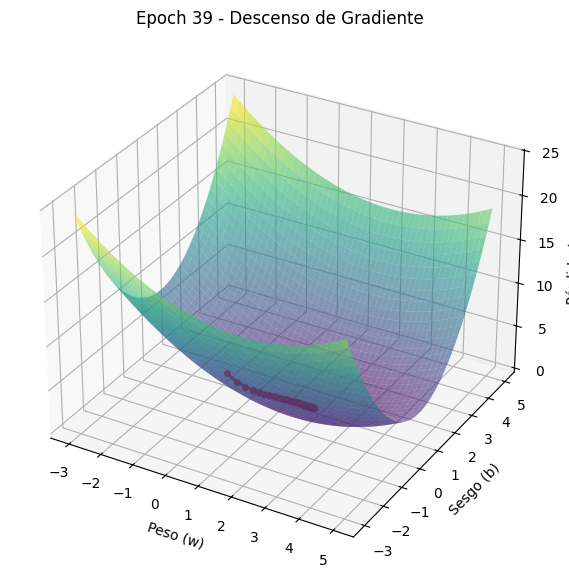

 Entrenamiento completado
Peso final: 1.837, Sesgo final: 1.024


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import clear_output
import time

# Datos simples (una línea con ruido)
X = np.linspace(-1, 1, 100)
Y = 2 * X + 1 + np.random.randn(*X.shape) * 0.2

X_tf = tf.constant(X, dtype=tf.float32)
Y_tf = tf.constant(Y, dtype=tf.float32)

# Variables del modelo
w = tf.Variable(tf.random.normal([1]))
b = tf.Variable(tf.random.normal([1]))
lr = 0.1
optimizer = tf.keras.optimizers.SGD(learning_rate=lr)

# Crear una malla de valores posibles de w y b
W_range = np.linspace(-3, 5, 50)
B_range = np.linspace(-3, 5, 50)
W, B = np.meshgrid(W_range, B_range)

# Calcular la pérdida (MSE) para cada par (w, b)
Loss = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        Y_pred = W[i, j] * X + B[i, j]
        Loss[i, j] = np.mean((Y - Y_pred) ** 2)

# Entrenamiento y animación
path_w, path_b, path_loss = [], [], []

for epoch in range(40):
    with tf.GradientTape() as tape:
        Y_pred = w * X_tf + b
        loss = tf.reduce_mean(tf.square(Y_tf - Y_pred))

    gradients = tape.gradient(loss, [w, b])
    optimizer.apply_gradients(zip(gradients, [w, b]))

    # Guardar valores para la trayectoria
    path_w.append(w.numpy()[0])
    path_b.append(b.numpy()[0])
    path_loss.append(loss.numpy())

    # Graficar
    clear_output(wait=True)
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(W, B, Loss, cmap='viridis', alpha=0.6)
    ax.plot(path_w, path_b, path_loss, color='r', marker='o', markersize=4, linewidth=2)
    ax.set_xlabel('Peso (w)')
    ax.set_ylabel('Sesgo (b)')
    ax.set_zlabel('Pérdida (Loss)')
    ax.set_title(f'Epoch {epoch} - Descenso de Gradiente')
    plt.show()

    time.sleep(0.3)

print(" Entrenamiento completado")
print(f"Peso final: {w.numpy()[0]:.3f}, Sesgo final: {b.numpy()[0]:.3f}")

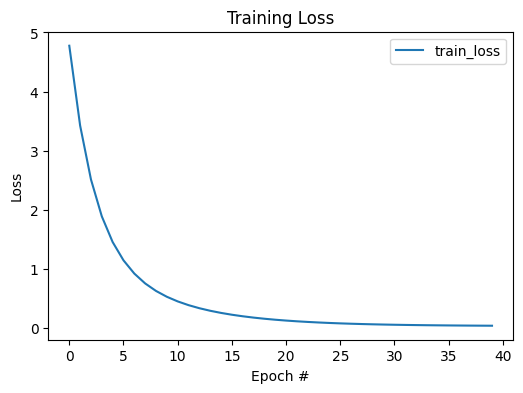

In [3]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(0, len(path_loss)), path_loss, label="train_loss")
plt.title("Training Loss")
plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [4]:
plt.style.use("ggplot")
plt.figure(figsize=(6, 4))
plt.plot(np.arange(0, len(history.history["accuracy"])), history.history["accuracy"], label="train_accuracy")
plt.plot(np.arange(0, len(history.history["val_accuracy"])), history.history["val_accuracy"], label="val_accuracy")
plt.title("Train and Test Accuracy")
plt.xlabel("Epoch #")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

NameError: name 'history' is not defined

<Figure size 600x400 with 0 Axes>

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Aplanar las imágenes de prueba a (10000, 784)
X_test_flat = X_test.reshape(X_test.shape[0], 28*28)

# Realizar predicciones con el modelo
y_pred_probs = model.predict(X_test_flat)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true = y_test  # etiquetas reales (0–9)

# Identificar los índices de las imágenes mal clasificadas
misclassified_indices = np.where(y_pred_classes != y_true)[0]

print(f"Total de imágenes mal clasificadas: {len(misclassified_indices)}")

# Mostrar algunas imágenes mal clasificadas
num_images = 25  # puedes ajustar este número
plt.figure(figsize=(10, 10))

for i, index in enumerate(misclassified_indices[:num_images]):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_test[index], cmap='gray')  # aquí mostramos la original 28x28
    plt.title(f"Pred: {y_pred_classes[index]} / Real: {y_true[index]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

NameError: name 'X_test' is not defined